# Corporate Tweet Political / Public Policy Discussion Classification - Zero-Shot Classification


## Overview

This notebook classifies **all corporate tweets** (not just an LGBTQ+-labeled subset) according to whether they contain political or public policy discussion:

| Label | Description | Example |
|-------|-------------|--------|
| **Political or Public Policy Discussion** | References legislation, elections, government policy, regulation, or political positions | "We urge Congress to pass paid family leave legislation this session" |
| **Non-Political** | General business, product, marketing, or unrelated content | "Check out our new fall product line, available now!" |

### Why Zero-Shot Classification?

Topic modeling (like LDA) finds themes automatically but doesn't know which categories we want in advance, we'd have to guess what the output means. Zero-shot classification works the other way: we tell it our two labels and it scores each tweet against them directly. This is better suited to this task because the categories are already defined by the research goals.

The model used is `facebook/bart-large-mnli` — a pre-trained model that understands natural language and does not require any training data from our dataset.

### Two-Label Probability Scoring

Every tweet gets a probability for **both** labels — `political_probability` and `non_political_probability` (these sum to 1, since the classifier is run in single-label mode across the two candidate labels). The primary output of this notebook is `political_probability`; a `predicted_label` column is also kept as a convenience, but the continuous probability is what the rest of the analysis uses.


---
## Section 1 — Setup


### 1.1 — Install & Import Libraries


In [1]:
# ── Install Hugging Face transformers (includes zero-shot pipeline) ───────────
!pip install transformers torch --quiet

In [2]:
# ── Core libraries ───────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from IPython.display import display
import warnings
import time
import os
warnings.filterwarnings('ignore')

# ── Hugging Face zero-shot pipeline ─────────────────────────────────────────
from transformers import pipeline

# ── Plot styling (matches LGBTQ+ notebook) ──────────────────────────────────
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.15)
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
    'figure.titlesize': 16,
    'figure.titleweight': 'bold',
})

# ── Colors ───────────────────────────────────────────────────────────────────
POLITICAL_COLOR     = '#EF4444'   # red
NON_POLITICAL_COLOR = '#64748B'   # slate gray
ACCENT_COLOR         = '#F59E0B'  # amber

# One color per label
CAT_COLORS = {
    'Political'     : POLITICAL_COLOR,
    'Non-Political' : NON_POLITICAL_COLOR,
}

print('✅ Libraries imported successfully.')

✅ Libraries imported successfully.


### 1.2 — Load Dataset

Unlike the LGBTQ+ notebook, this notebook works on the **entire corporate tweet dataset** — there is no LGBTQ+ subset filter.


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
FILE_PATH = '/content/drive/MyDrive/Colab Notebooks/Tweets.csv'

df = pd.read_csv(FILE_PATH, low_memory=False, on_bad_lines='skip')
# ── Parse dates ──────────────────────────────────────────────────────────────
df['createdAt'] = pd.to_datetime(df['createdAt'], utc=True, errors='coerce')
df['year']      = df['createdAt'].dt.year
df['month']     = df['createdAt'].dt.month

print(f'✅ Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns')
print(f'   Companies : {df["author_userName"].nunique():,}')

# ── Detect engagement columns available in this dataset ─────────────────────
# Used later in the Engagement Analysis section. Not every export of this
# dataset has the same engagement fields, so we check what's actually present.
ENGAGEMENT_CANDIDATES = ['likeCount', 'retweetCount', 'replyCount', 'quoteCount', 'viewCount', 'bookmarkCount']
ENGAGEMENT_COLS = [c for c in ENGAGEMENT_CANDIDATES if c in df.columns]
print(f'   Engagement columns found: {ENGAGEMENT_COLS if ENGAGEMENT_COLS else "none"}')

✅ Dataset loaded: 1,585,500 rows × 19 columns
   Companies : 398
   Engagement columns found: ['likeCount', 'retweetCount', 'replyCount', 'quoteCount']


### 1.3 — Development Sampling

Because the full dataset is very large, this notebook can run on a **random development sample** while the pipeline is being built and tested, then be pointed at the full dataset with a single flag flip.

- `USE_SAMPLE = True` → randomly sample `SAMPLE_SIZE` tweets before classification.
- `USE_SAMPLE = False` → use the entire dataset.

Nothing downstream needs to change between the two modes — every later cell reads from `df_tweets`, regardless of whether it holds a sample or the full dataset.

In [7]:
# ── Sampling controls ─────────────────────────────────────────────────────────
# Set USE_SAMPLE = False (or delete/skip this cell) to run on the full dataset.
USE_SAMPLE   = True
SAMPLE_SIZE  = 5000
RANDOM_STATE = 42

if USE_SAMPLE:
    df_tweets = (
        df.sample(n=min(SAMPLE_SIZE, len(df)), random_state=RANDOM_STATE)
        .copy()
        .reset_index(drop=True)
    )
    print(f'✅ Development sample: {len(df_tweets):,} tweets  '
          f'(USE_SAMPLE=True, SAMPLE_SIZE={SAMPLE_SIZE:,}, RANDOM_STATE={RANDOM_STATE})')
else:
    df_tweets = df.copy().reset_index(drop=True)
    print(f'✅ Using full dataset: {len(df_tweets):,} tweets  (USE_SAMPLE=False)')

# Clean text — remove nulls
df_tweets['text'] = df_tweets['text'].fillna('').astype(str)

print(f'   Companies : {df_tweets["author_userName"].nunique():,}')
print(f'   Date range: {df_tweets["createdAt"].min().date()}  →  {df_tweets["createdAt"].max().date()}')

✅ Development sample: 5,000 tweets  (USE_SAMPLE=True, SAMPLE_SIZE=5,000, RANDOM_STATE=42)
   Companies : 359
   Date range: 2018-01-01  →  2024-07-14


---
## Section 2 — Define Labels & Load Model


### 2.1 — Label Definitions

The labels below are what the model scores each tweet against. The wording matters — clear, descriptive labels produce better results than single words.

In [8]:
# ── Two research labels ───────────────────────────────────────────────────────
# These are passed directly to the zero-shot classifier as candidate labels.
# Changes to wording can be done here if needed.
CANDIDATE_LABELS = [
    'political or public policy discussion, legislation, elections, or government action',
    'non-political general business, product, marketing, or unrelated content',
]

# Shorter display names mapped to those labels (used in charts and tables)
LABEL_MAP = {
    'political or public policy discussion, legislation, elections, or government action' : 'Political',
    'non-political general business, product, marketing, or unrelated content'              : 'Non-Political',
}

cat_order = ['Political', 'Non-Political']

print('Labels defined:')
for short, full in zip(LABEL_MAP.values(), LABEL_MAP.keys()):
    print(f'  [{short}]  →  "{full}"')

Labels defined:
  [Political]  →  "political or public policy discussion, legislation, elections, or government action"
  [Non-Political]  →  "non-political general business, product, marketing, or unrelated content"


### 2.2 — Load Zero-Shot Classifier

This downloads the `facebook/bart-large-mnli` model

In [9]:
# ── Load the zero-shot classification pipeline ───────────────────────────────
# device=0 uses the GPU (much faster); device=-1 uses CPU (slower but works)
print('Loading model... (downloads ~1.6 GB on first run, then cached)')

classifier = pipeline(
    'zero-shot-classification',
    model='facebook/bart-large-mnli',
    device=0   # GPU — change to -1 if you did not enable GPU runtime
)

print('✅ Model loaded and ready.')

Loading model... (downloads ~1.6 GB on first run, then cached)


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

✅ Model loaded and ready.


### 2.3 — Quick Test on 5 Tweets

Testing the classifier on a small sample before running the full dataset. Both probabilities are printed for every tweet — remember they sum to 1, since only two candidate labels are used.

In [10]:
# ── Test on 5 sample tweets ──────────────────────────────────────────────────
test_tweets = df_tweets['text'].sample(5, random_state=42).tolist()

print('CLASSIFIER TEST — 5 SAMPLE TWEETS')
print('═' * 60)

for tweet in test_tweets:
    result = classifier(tweet[:512], CANDIDATE_LABELS)
    scores_by_cat = {LABEL_MAP[l]: s for l, s in zip(result['labels'], result['scores'])}
    predicted = LABEL_MAP[result['labels'][0]]

    print(f'\nTweet   : "{tweet[:120]}"')
    print(f'  Political probability     : {scores_by_cat["Political"]:.3f}')
    print(f'  Non-Political probability : {scores_by_cat["Non-Political"]:.3f}')
    print(f'  Predicted label           : {predicted}')
    print()

print('═' * 60)
print('\n✅ Test complete. Review results above before running full classification.')
print('   If any labels look wrong, adjust the CANDIDATE_LABELS wording in Section 2.1.')

---
## Section 3 — Run Full Classification

This is the main processing step. It runs the classifier on every tweet in `df_tweets` (the development sample, or the full dataset if `USE_SAMPLE = False`) in batches, keeping both label probabilities for every tweet.

In [11]:
CHECKPOINT_PATH = '/content/drive/MyDrive/political_classified_checkpoint.csv'
BATCH_SIZE      = 32    # tweets per batch — GPU handles this comfortably
SAVE_EVERY      = 1000  # save checkpoint every N tweets

# ── Resume from checkpoint if one exists ────────────────────────────────────
if os.path.exists(CHECKPOINT_PATH):
    df_done = pd.read_csv(CHECKPOINT_PATH)
    done_indices = set(df_done['original_index'].tolist())
    print(f'✅ Checkpoint found: {len(df_done):,} tweets already classified. Resuming...')
else:
    df_done = pd.DataFrame()
    done_indices = set()
    print('No checkpoint found. Starting from scratch.')

# ── Identify remaining tweets ────────────────────────────────────────────────
remaining = df_tweets[~df_tweets.index.isin(done_indices)].copy()
print(f'Tweets remaining to classify: {len(remaining):,}')
print(f'Estimated time (GPU): ~{len(remaining)//60//60}h {(len(remaining)//60)%60}m')

# ── Run classification in batches ────────────────────────────────────────────
results = []
texts   = remaining['text'].tolist()
indices = remaining.index.tolist()

start_time = time.time()

for i in range(0, len(texts), BATCH_SIZE):
    batch_texts   = [t[:512] for t in texts[i:i+BATCH_SIZE]]   # truncate to model max
    batch_indices = indices[i:i+BATCH_SIZE]

    batch_results = classifier(batch_texts, CANDIDATE_LABELS, batch_size=BATCH_SIZE)

    for idx, res in zip(batch_indices, batch_results):
        scores_by_cat = {LABEL_MAP[l]: s for l, s in zip(res['labels'], res['scores'])}
        predicted     = LABEL_MAP[res['labels'][0]]

        results.append({
            'original_index'          : idx,
            'political_probability'  : round(scores_by_cat['Political'], 4),
            'non_political_probability': round(scores_by_cat['Non-Political'], 4),
            'predicted_label'         : predicted,
        })

    # ── Progress update and checkpoint ───────────────────────────────────────
    processed = len(results)
    if processed % SAVE_EVERY < BATCH_SIZE or i + BATCH_SIZE >= len(texts):
        elapsed  = time.time() - start_time
        rate     = processed / elapsed if elapsed > 0 else 1
        remaining_t = (len(texts) - processed) / rate
        print(f'  [{processed:>6,} / {len(texts):,}]  '
              f'Speed: {rate:.0f} tweets/sec  '
              f'ETA: {remaining_t/60:.0f} min')

        # Save checkpoint
        batch_df = pd.DataFrame(results)
        combined = pd.concat([df_done, batch_df], ignore_index=True) if len(df_done) > 0 else batch_df
        combined.to_csv(CHECKPOINT_PATH, index=False)

print(f'\n✅ Classification complete!')

No checkpoint found. Starting from scratch.
Tweets remaining to classify: 5,000
Estimated time (GPU): ~1h 23m


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


  [ 1,024 / 5,000]  Speed: 22 tweets/sec  ETA: 3 min
  [ 2,016 / 5,000]  Speed: 21 tweets/sec  ETA: 2 min
  [ 3,008 / 5,000]  Speed: 21 tweets/sec  ETA: 2 min
  [ 4,000 / 5,000]  Speed: 21 tweets/sec  ETA: 1 min
  [ 5,000 / 5,000]  Speed: 20 tweets/sec  ETA: 0 min

✅ Classification complete!


In [12]:
# ── Merge classification results back onto the tweet dataframe ──────────────
classified = pd.read_csv(CHECKPOINT_PATH)
classified = classified.set_index('original_index')

df_tweets = df_tweets.join(classified, how='left')

# ── Save final merged file ───────────────────────────────────────────────────
# Final dataframe contains: original tweet info + political_probability +
# non_political_probability + predicted_label. Probabilities are NOT collapsed
# to a binary outcome — they stay available for every analysis below.
df_tweets.to_csv('/content/drive/MyDrive/political_tweets_classified.csv', index=False)

print(f'✅ Results merged. Classified: {df_tweets["political_probability"].notna().sum():,} tweets')
print(f'   Saved to: political_tweets_classified.csv')
print(f'\nPredicted label distribution:')
print(df_tweets['predicted_label'].value_counts().to_string())

✅ Results merged. Classified: 5,000 tweets
   Saved to: political_tweets_classified.csv

Predicted label distribution:
predicted_label
Non-Political    4269
Political         731


---
## Section 4 — Overall Political Probability Distribution

How political is the corporate tweet dataset overall? We look at both the continuous `political_probability` distribution and the resulting `predicted_label` split.

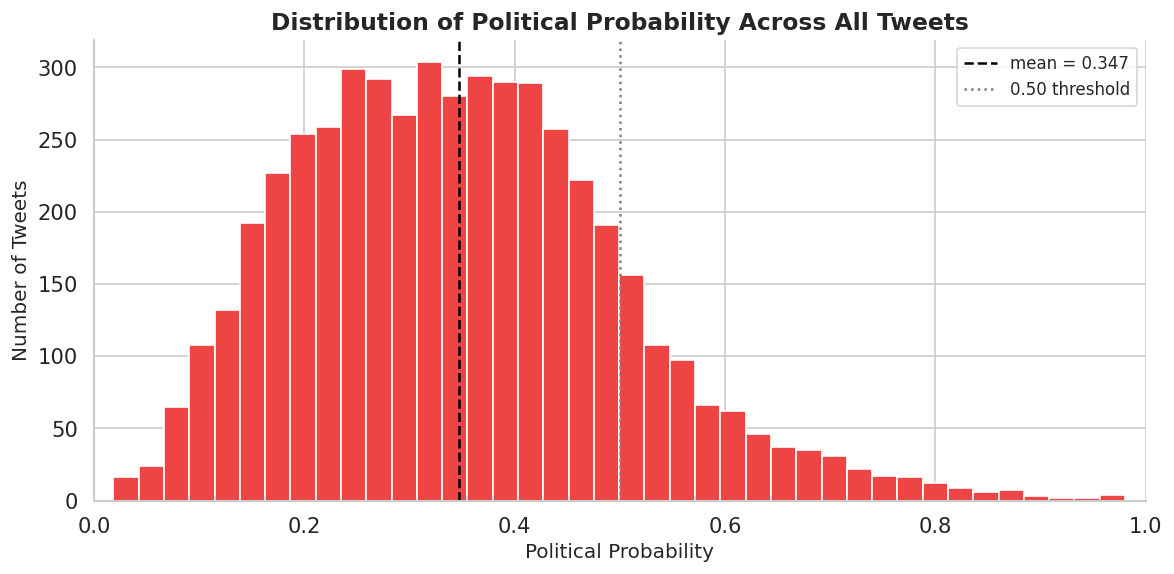

SUMMARY STATISTICS — political_probability


,Value
count,5000.000
mean,0.347
std,0.153
min,0.018
25%,0.232
50%,0.336
75%,0.443
max,0.980


In [13]:
# ── Histogram of political probability ───────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df_tweets['political_probability'].dropna(), bins=40,
        color=POLITICAL_COLOR, edgecolor='white')
ax.axvline(df_tweets['political_probability'].mean(), color='black', linestyle='--',
           linewidth=1.5, label=f'mean = {df_tweets["political_probability"].mean():.3f}')
ax.axvline(0.5, color='gray', linestyle=':', linewidth=1.5, label='0.50 threshold')
ax.set_title('Distribution of Political Probability Across All Tweets')
ax.set_xlabel('Political Probability')
ax.set_ylabel('Number of Tweets')
ax.set_xlim(0, 1)
ax.legend(fontsize=10)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig('fig_political_prob_dist.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Summary statistics ────────────────────────────────────────────────────────
prob_stats = df_tweets['political_probability'].describe().round(3)
print('SUMMARY STATISTICS — political_probability')
display(prob_stats.to_frame(name='Value'))

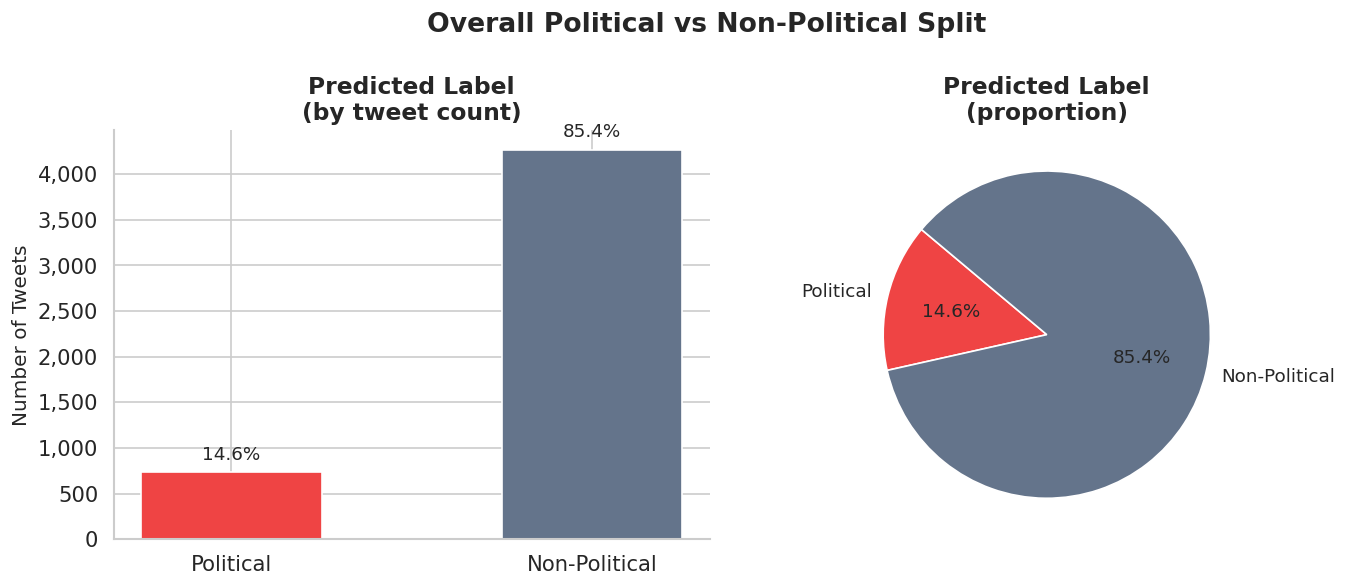

In [14]:
# ── Predicted label distribution (bar + pie) ─────────────────────────────────
cat_colors = [CAT_COLORS[c] for c in cat_order]
cat_counts = df_tweets['predicted_label'].value_counts().reindex(cat_order).fillna(0)
cat_pcts   = (cat_counts / cat_counts.sum() * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

bars = axes[0].bar(cat_order, cat_counts, color=cat_colors, edgecolor='white', width=0.5)
axes[0].bar_label(bars, labels=[f'{p:.1f}%' for p in cat_pcts], padding=5, fontsize=11)
axes[0].set_title('Predicted Label\n(by tweet count)')
axes[0].set_ylabel('Number of Tweets')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
sns.despine(ax=axes[0])

axes[1].pie(
    cat_counts, labels=cat_order, colors=cat_colors,
    autopct='%1.1f%%', startangle=140, textprops={'fontsize': 11}
)
axes[1].set_title('Predicted Label\n(proportion)')

fig.suptitle('Overall Political vs Non-Political Split')
plt.tight_layout()
plt.savefig('fig_predicted_label_dist.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 5 — Political Probability Trends Over Time

Has the amount of political content in corporate tweets shifted over time?

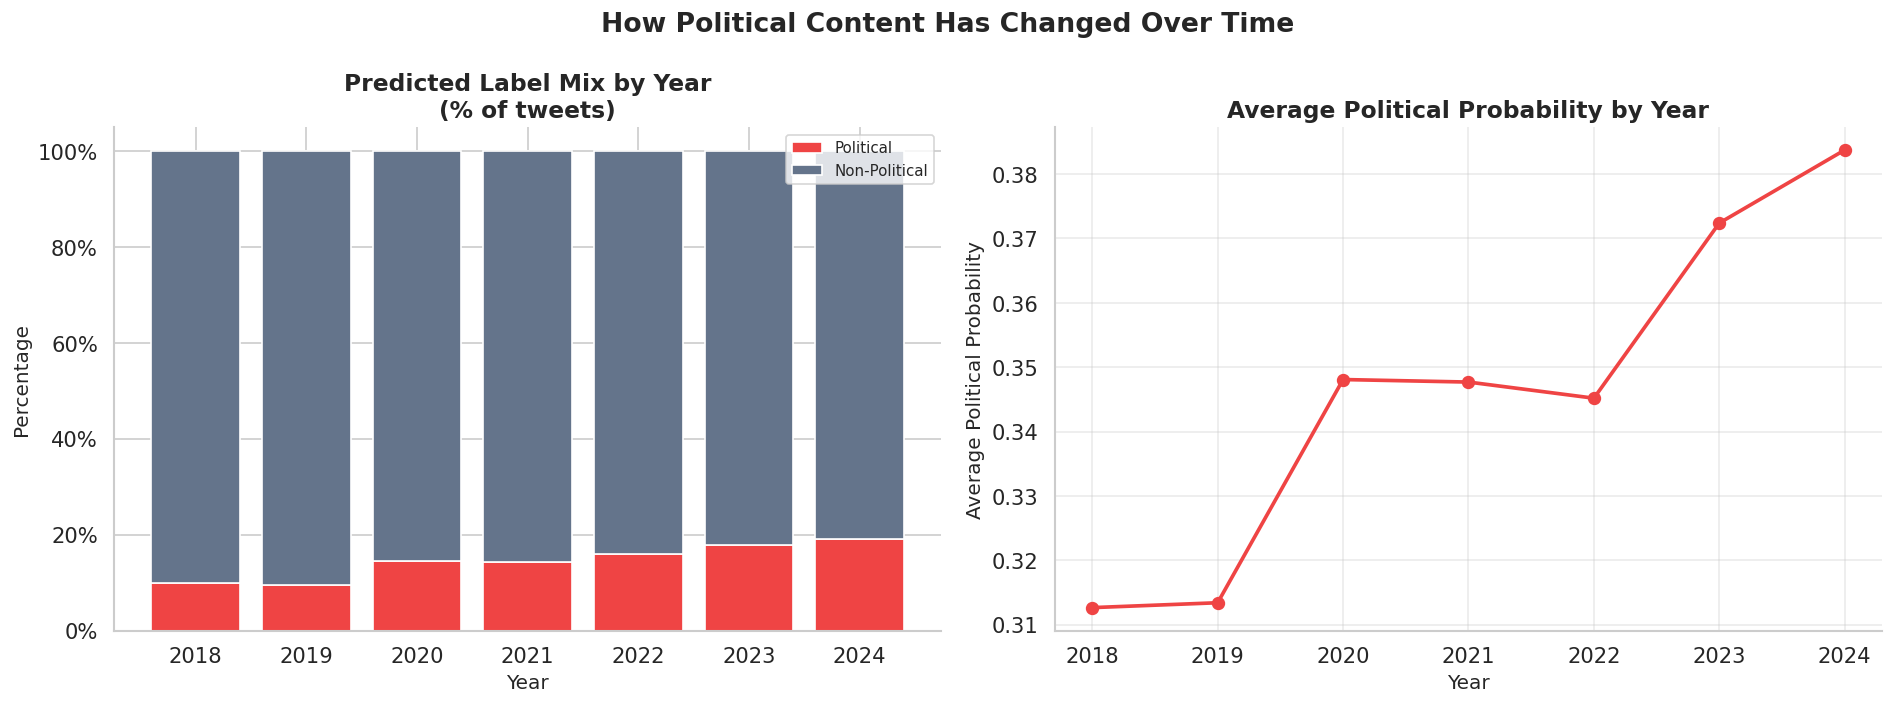

In [15]:
# ── Predicted label % by year, and average political probability by year ───
yearly_cats = (
    df_tweets.groupby(['year', 'predicted_label'])
    .size()
    .reset_index(name='count')
)
yearly_pivot     = yearly_cats.pivot(index='year', columns='predicted_label', values='count').fillna(0)
yearly_pivot_pct = yearly_pivot.div(yearly_pivot.sum(axis=1), axis=0) * 100

yearly_avg_prob = df_tweets.groupby('year')['political_probability'].mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Percentage stacked bars
bottom = np.zeros(len(yearly_pivot_pct))
for cat in cat_order:
    if cat in yearly_pivot_pct.columns:
        vals = yearly_pivot_pct[cat].values
        axes[0].bar(yearly_pivot_pct.index, vals, bottom=bottom,
                    label=cat, color=CAT_COLORS[cat], edgecolor='white')
        bottom += vals

axes[0].set_title('Predicted Label Mix by Year\n(% of tweets)')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Percentage')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}%'))
axes[0].legend(loc='upper right', fontsize=9)
axes[0].set_xticks(yearly_pivot_pct.index)
sns.despine(ax=axes[0])

# Average political probability line
axes[1].plot(yearly_avg_prob.index, yearly_avg_prob.values, marker='o',
             linewidth=2.2, color=POLITICAL_COLOR, markersize=7)
axes[1].set_title('Average Political Probability by Year')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Average Political Probability')
axes[1].set_xticks(yearly_avg_prob.index)
axes[1].grid(True, alpha=0.4)
sns.despine(ax=axes[1])

fig.suptitle('How Political Content Has Changed Over Time')
plt.tight_layout()
plt.savefig('fig_political_yearly_trend.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 6 — Political Probability by Month (Seasonality)


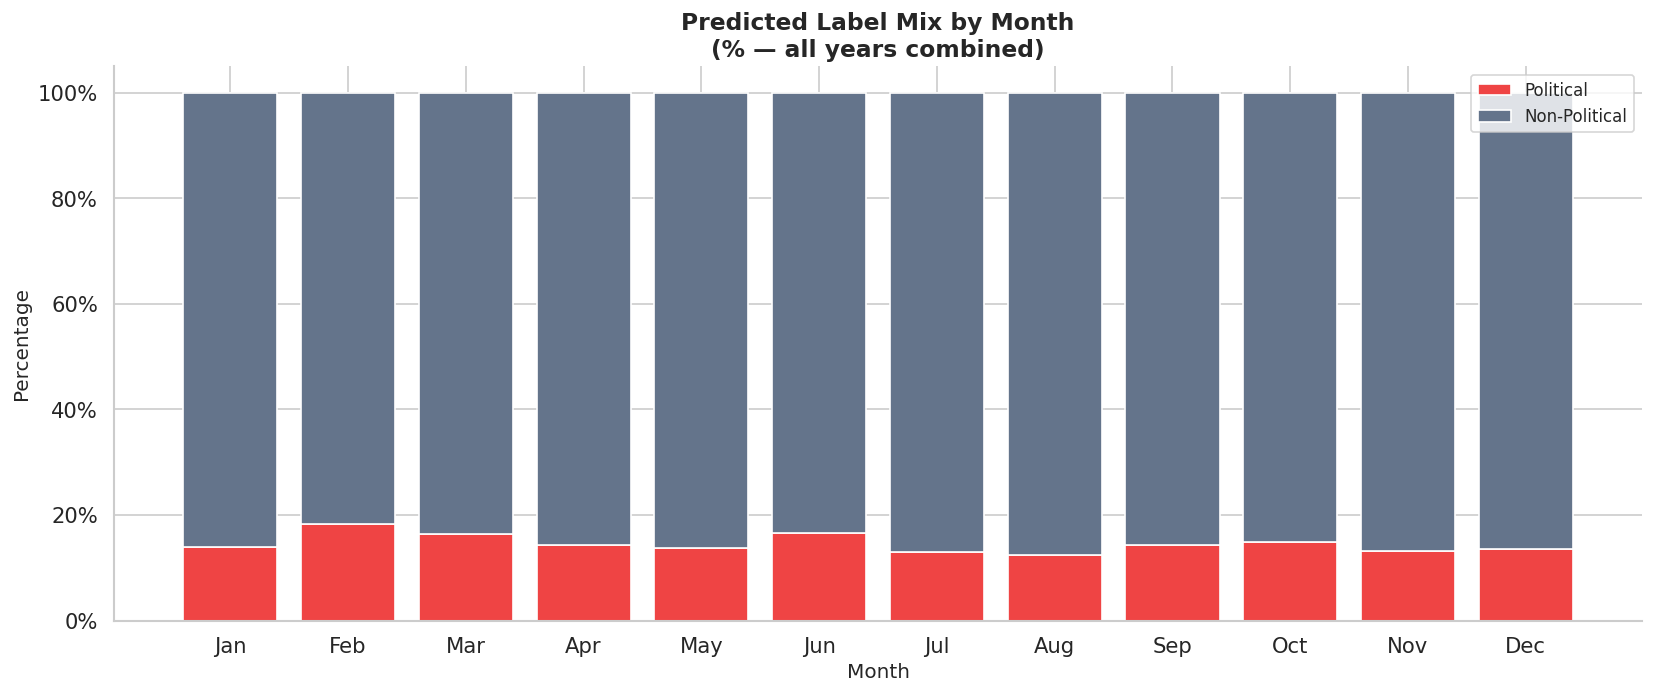

In [16]:
month_names = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']

monthly_cats = (
    df_tweets.groupby(['month', 'predicted_label'])
    .size()
    .reset_index(name='count')
)
monthly_pivot     = monthly_cats.pivot(index='month', columns='predicted_label', values='count').fillna(0)
monthly_pivot_pct = monthly_pivot.div(monthly_pivot.sum(axis=1), axis=0) * 100
monthly_pivot_pct.index = [month_names[m-1] for m in monthly_pivot_pct.index]

fig, ax = plt.subplots(figsize=(14, 6))

bottom = np.zeros(len(monthly_pivot_pct))
for cat in cat_order:
    if cat in monthly_pivot_pct.columns:
        vals = monthly_pivot_pct[cat].values
        ax.bar(monthly_pivot_pct.index, vals, bottom=bottom,
               label=cat, color=CAT_COLORS[cat], edgecolor='white')
        bottom += vals

ax.set_title('Predicted Label Mix by Month\n(% — all years combined)')
ax.set_xlabel('Month')
ax.set_ylabel('Percentage')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}%'))
ax.legend(loc='upper right', fontsize=10)
sns.despine()
plt.tight_layout()
plt.savefig('fig_political_monthly.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 7 — Political Probability by Company

Which companies talk about politics and public policy most? We look at the top 20 companies by tweet volume, and separately at the top and bottom companies ranked purely by average political probability.

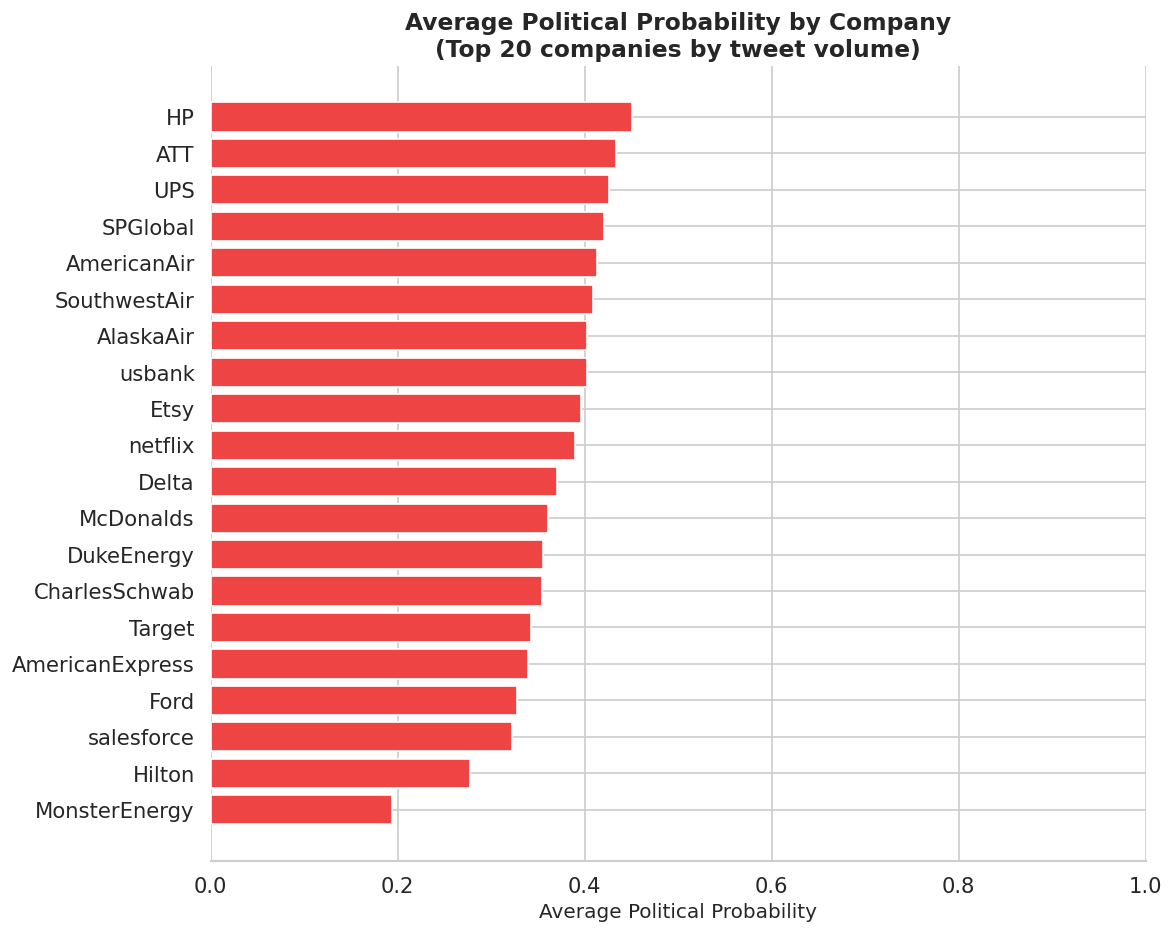

In [17]:
# ── Average political probability for top 20 companies by tweet volume ──────
top20_companies = (
    df_tweets['author_userName']
    .value_counts()
    .head(20)
    .index.tolist()
)

company_avg = (
    df_tweets[df_tweets['author_userName'].isin(top20_companies)]
    .groupby('author_userName')['political_probability']
    .mean()
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(company_avg.index, company_avg.values, color=POLITICAL_COLOR, edgecolor='white')
ax.set_title('Average Political Probability by Company\n(Top 20 companies by tweet volume)')
ax.set_xlabel('Average Political Probability')
ax.set_xlim(0, 1)
sns.despine(ax=ax, left=True)
plt.tight_layout()
plt.savefig('fig_political_by_company.png', dpi=150, bbox_inches='tight')
plt.show()

In [18]:
# ── Top and bottom companies by average political probability ──────────────
# Restricted to companies with at least MIN_TWEETS tweets so the ranking isn't
# dominated by companies with only one or two tweets.
MIN_TWEETS = 20

company_stats = (
    df_tweets.groupby('author_userName')
    .agg(avg_political_probability=('political_probability', 'mean'),
         tweet_count=('political_probability', 'size'))
    .query('tweet_count >= @MIN_TWEETS')
    .sort_values('avg_political_probability', ascending=False)
)

print(f'Companies with ≥{MIN_TWEETS} tweets: {len(company_stats):,}')

print('\nTOP 10 MOST POLITICAL COMPANIES (by average probability)')
display(company_stats.head(10).style.format({'avg_political_probability': '{:.3f}',
                                              'tweet_count': '{:,}'}))

print('\nBOTTOM 10 LEAST POLITICAL COMPANIES (by average probability)')
display(company_stats.tail(10).sort_values('avg_political_probability').style.format(
    {'avg_political_probability': '{:.3f}', 'tweet_count': '{:,}'}))

Companies with ≥20 tweets: 56

TOP 10 MOST POLITICAL COMPANIES (by average probability)


,avg_political_probability,tweet_count
author_userName,,
WellsFargo,0.501,29
MetLife,0.465,20
HP,0.451,66
MSCI_Inc,0.449,21
InsidePMI,0.444,23
Intuit,0.436,22
ATT,0.434,62
UPS,0.426,59
Humana,0.425,27



BOTTOM 10 LEAST POLITICAL COMPANIES (by average probability)


,avg_political_probability,tweet_count
author_userName,,
MonsterEnergy,0.194,96
Equinix,0.231,25
MicrochipTech,0.236,36
PublicStorage,0.243,38
WestPharma,0.266,26
Clorox,0.276,32
MolsonCoors,0.277,31
Hilton,0.277,77
Cisco,0.295,22


---
## Section 8 — Threshold Analysis

Rather than looking only at the binary `predicted_label`, it's useful to see how the share of tweets changes at different political-probability thresholds.

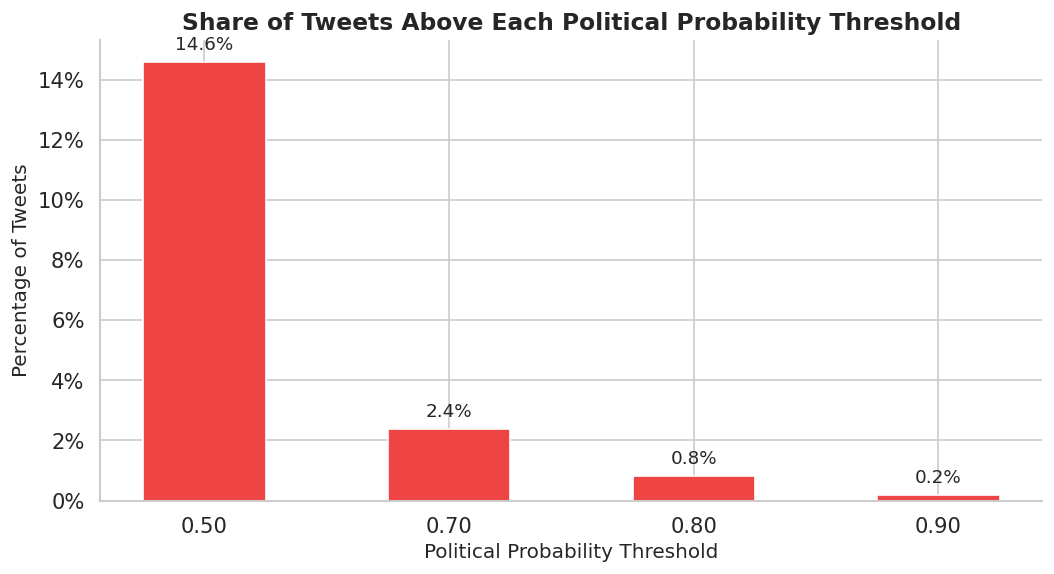

THRESHOLD ANALYSIS


Threshold,Tweets,Percentage
> 0.50,730,14.6%
> 0.70,119,2.4%
> 0.80,40,0.8%
> 0.90,9,0.2%


In [19]:
# ── Proportion of tweets above common thresholds ─────────────────────────────
THRESHOLDS = [0.50, 0.70, 0.80, 0.90]

threshold_props = pd.DataFrame([
    {'Threshold': f'> {t:.2f}',
     'Tweets': (df_tweets['political_probability'] > t).sum(),
     'Percentage': (df_tweets['political_probability'] > t).mean() * 100}
    for t in THRESHOLDS
])

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar([f'{t:.2f}' for t in THRESHOLDS], threshold_props['Percentage'],
              color=POLITICAL_COLOR, edgecolor='white', width=0.5)
ax.bar_label(bars, labels=[f'{p:.1f}%' for p in threshold_props['Percentage']], padding=5, fontsize=11)
ax.set_title('Share of Tweets Above Each Political Probability Threshold')
ax.set_xlabel('Political Probability Threshold')
ax.set_ylabel('Percentage of Tweets')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}%'))
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig('fig_threshold_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print('THRESHOLD ANALYSIS')
display(threshold_props.style.format({'Tweets': '{:,}', 'Percentage': '{:.1f}%'}).hide(axis='index'))

---
## Section 9 — Example Tweets Across Probability Ranges

Reviewing examples confirms the classifier is working correctly — the highest and lowest scoring tweets, plus a sample from every probability bin in between.

In [20]:
# ── Top 10 highest political probability tweets ──────────────────────────────
top_political = (
    df_tweets.nlargest(10, 'political_probability')
    [['author_userName', 'text', 'political_probability']]
    .reset_index(drop=True)
)
print('TOP 10 HIGHEST POLITICAL PROBABILITY TWEETS')
print('═' * 65)
for _, row in top_political.iterrows():
    print(f'  [{row["author_userName"]}]  political_probability={row["political_probability"]:.3f}')
    print(f'  "{row["text"][:160]}"')
    print()

In [21]:
# ── Top 10 lowest political probability tweets ───────────────────────────────
bottom_political = (
    df_tweets.nsmallest(10, 'political_probability')
    [['author_userName', 'text', 'political_probability']]
    .reset_index(drop=True)
)
print('TOP 10 LOWEST POLITICAL PROBABILITY TWEETS (most confidently non-political)')
print('═' * 65)
for _, row in bottom_political.iterrows():
    print(f'  [{row["author_userName"]}]  political_probability={row["political_probability"]:.3f}')
    print(f'  "{row["text"][:160]}"')
    print()

In [22]:
# ── Sample tweets across probability ranges ──────────────────────────────────
prob_bins = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
bin_labels = ['0.0–0.2', '0.2–0.4', '0.4–0.6', '0.6–0.8', '0.8–1.0']

df_tweets['probability_bin'] = pd.cut(df_tweets['political_probability'],
                                       bins=prob_bins, labels=bin_labels, include_lowest=True)

for label in bin_labels:
    subset = df_tweets[df_tweets['probability_bin'] == label]
    print(f'\n{"═"*65}')
    print(f'  PROBABILITY RANGE {label}   ({len(subset):,} tweets)')
    print(f'{"═"*65}')
    if len(subset) == 0:
        print('  (no tweets in this range)')
        continue
    sample = subset.sample(min(3, len(subset)), random_state=42)
    for _, row in sample.iterrows():
        print(f'  [{row["author_userName"]}]  political_probability={row["political_probability"]:.3f}')
        print(f'  "{row["text"][:150]}"')
        print()

---
## Section 10 — Engagement Analysis

Do political tweets get more or less engagement than non-political tweets? This section compares engagement metrics between high-political and low-political tweets, and checks the correlation between political probability and engagement.

High-political tweets: 119   Low-political tweets: 2,055

AVERAGE ENGAGEMENT: HIGH-POLITICAL vs LOW-POLITICAL


,High-Political (>0.70),Low-Political (<0.30)
likeCount,82.8,55.4
retweetCount,10.0,6.9
replyCount,4.7,2.2
quoteCount,2.8,1.2


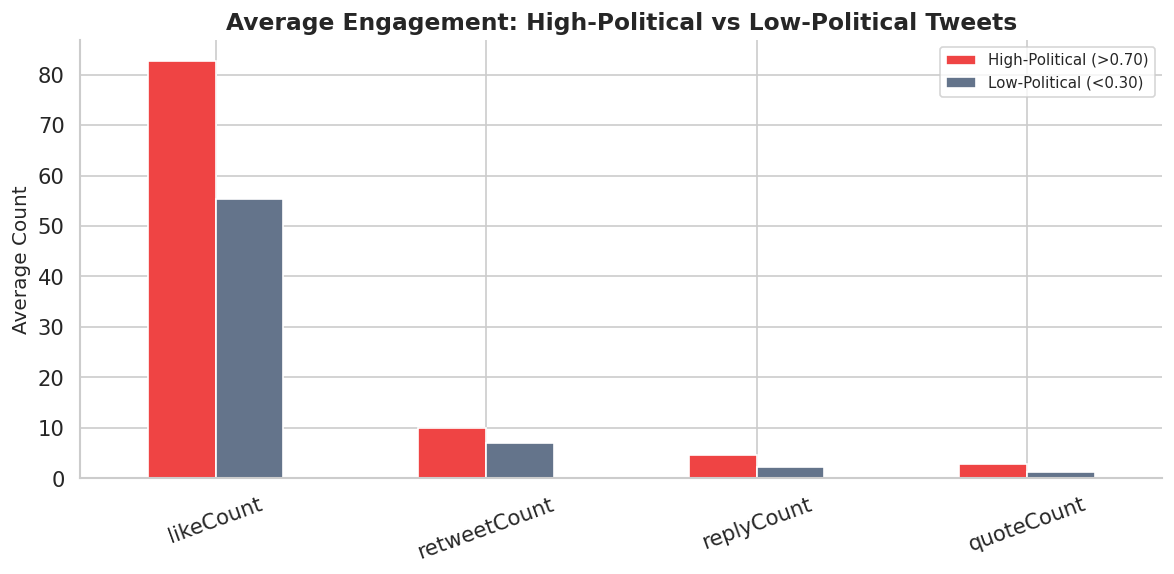


CORRELATION: political_probability vs engagement metrics


,Correlation with political_probability
quoteCount,0.015
replyCount,0.010
likeCount,0.010
retweetCount,0.008


In [23]:
if not ENGAGEMENT_COLS:
    print('⚠️  No engagement columns were found in this dataset '
          f'(checked for: {ENGAGEMENT_CANDIDATES}). Skipping engagement analysis.')
else:
    # ── High-political vs low-political comparison ───────────────────────────
    HIGH_THRESHOLD = 0.70
    LOW_THRESHOLD  = 0.30

    high_political = df_tweets[df_tweets['political_probability'] > HIGH_THRESHOLD]
    low_political  = df_tweets[df_tweets['political_probability'] < LOW_THRESHOLD]

    comparison = pd.DataFrame({
        f'High-Political (>{HIGH_THRESHOLD:.2f})': high_political[ENGAGEMENT_COLS].mean(),
        f'Low-Political (<{LOW_THRESHOLD:.2f})'   : low_political[ENGAGEMENT_COLS].mean(),
    }).round(1)

    print(f'High-political tweets: {len(high_political):,}   '
          f'Low-political tweets: {len(low_political):,}')
    print('\nAVERAGE ENGAGEMENT: HIGH-POLITICAL vs LOW-POLITICAL')
    display(comparison)

    fig, ax = plt.subplots(figsize=(10, 5))
    comparison.plot(kind='bar', ax=ax, color=[POLITICAL_COLOR, NON_POLITICAL_COLOR], edgecolor='white')
    ax.set_title('Average Engagement: High-Political vs Low-Political Tweets')
    ax.set_ylabel('Average Count')
    ax.tick_params(axis='x', rotation=20)
    ax.legend(fontsize=9)
    sns.despine(ax=ax)
    plt.tight_layout()
    plt.savefig('fig_engagement_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()

    # ── Correlation between political probability and engagement ─────────────
    corr = (
        df_tweets[['political_probability'] + ENGAGEMENT_COLS]
        .corr()['political_probability']
        .drop('political_probability')
        .sort_values(ascending=False)
    )
    print('\nCORRELATION: political_probability vs engagement metrics')
    display(corr.round(3).to_frame(name='Correlation with political_probability'))

---
## Section 11 — Borderline Tweets Review

Tweets with a political probability near 0.50 are the ones the classifier was least sure about — worth a quick manual review to spot any systematic errors, similar to the low-confidence review in the LGBTQ+ notebook.

In [24]:
BORDERLINE_LOW  = 0.45
BORDERLINE_HIGH = 0.55

borderline = df_tweets[
    df_tweets['political_probability'].between(BORDERLINE_LOW, BORDERLINE_HIGH)
].copy()

print(f'Borderline tweets ({BORDERLINE_LOW}–{BORDERLINE_HIGH} political probability): '
      f'{len(borderline):,}  ({len(borderline)/len(df_tweets)*100:.1f}% of total)')

print('\nSample borderline tweets:')
sample_borderline = borderline.sample(min(10, len(borderline)), random_state=42)
for _, row in sample_borderline.iterrows():
    print(f'  [{row["author_userName"]}]  political_probability={row["political_probability"]:.3f}')
    print(f'  "{row["text"][:150]}"')
    print()

Borderline tweets (0.45–0.55 political probability): 711  (14.2% of total)


---
## Section 12 — Summary

Auto-generated findings table based on the classification results.


In [25]:
total_classified   = df_tweets['political_probability'].notna().sum()
mean_political_prob = df_tweets['political_probability'].mean()
political_share     = (df_tweets['predicted_label'] == 'Political').mean() * 100
share_above_50      = (df_tweets['political_probability'] > 0.50).mean() * 100
share_above_80       = (df_tweets['political_probability'] > 0.80).mean() * 100
most_political_company = (
    df_tweets.groupby('author_userName')['political_probability'].mean().idxmax()
)

findings = pd.DataFrame([
    {'Metric': 'Total tweets classified',
     'Result': f'{total_classified:,}'},
    {'Metric': 'Mode',
     'Result': 'Development sample' if USE_SAMPLE else 'Full dataset'},
    {'Metric': 'Mean political probability',
     'Result': f'{mean_political_prob:.3f}'},
    {'Metric': 'Predicted-Political share',
     'Result': f'{political_share:.1f}%'},
    {'Metric': 'Tweets above 0.50 political probability',
     'Result': f'{share_above_50:.1f}%'},
    {'Metric': 'Tweets above 0.80 political probability',
     'Result': f'{share_above_80:.1f}%'},
    {'Metric': 'Most politically-focused company (by avg. probability)',
     'Result': most_political_company},
    {'Metric': 'Output file',
     'Result': 'political_tweets_classified.csv'},
])

print('CLASSIFICATION SUMMARY')
display(findings.style.hide(axis='index').set_properties(**{'text-align': 'left'}))

CLASSIFICATION SUMMARY


Metric,Result
Total tweets classified,"5,000"
Mode,Development sample
Mean political probability,0.347
Predicted-Political share,14.6%
Tweets above 0.50 political probability,14.6%
Tweets above 0.80 political probability,0.8%
Most politically-focused company (by avg. probability),AltriaNews
Output file,political_tweets_classified.csv


## Saved Files

**Figures:**
- `fig_political_prob_dist.png` — Histogram of political probability across all tweets
- `fig_predicted_label_dist.png` — Bar and pie chart of predicted label distribution
- `fig_political_yearly_trend.png` — Predicted label mix and average political probability by year
- `fig_political_monthly.png` — Predicted label mix by month
- `fig_political_by_company.png` — Average political probability by company (top 20 by volume)
- `fig_threshold_analysis.png` — Share of tweets above common probability thresholds
- `fig_engagement_comparison.png` — Average engagement: high-political vs low-political tweets (if engagement columns are present)

**Data:**
- `political_tweets_classified.csv` — Full tweet dataset (sample or complete, depending on `USE_SAMPLE`) with original tweet information plus:
  - `political_probability` — primary output; probability the tweet discusses politics/public policy
  - `non_political_probability` — complementary probability
  - `predicted_label` — `Political` or `Non-Political` (secondary/convenience column)
- `political_classified_checkpoint.csv` — Checkpoint file (safe to delete after run completes; resumable if the run is interrupted)

---
